# パーセプトロンのOR学習 / Interactive Perceptron Learning: OR

**Google Colab:** 「ランタイム → すべてのセルを実行」を選んでください。GPU・外部データ・APIキーは不要です。  
**Google Colab:** Choose **Runtime → Run all**. No GPU, external dataset, or API key is required.

センサーAまたはBが反応すると警報を出すOR問題です。図の点は正解、背景はモデルの予測、赤い輪は現在の誤分類を表します。  
This OR task triggers an alarm when either sensor is active. Point colors show targets, background colors show predictions, and red rings mark current mistakes.

### 操作 / Controls
1. **次へ / Next** で1サンプルずつ進みます。**再生 / Play**、巻き戻し、スライダーも使えます。  
   Use **Next** to process one sample; playback, rewind, and the slider are also available.
2. **更新のみ / Updates only** に切り替えると、スライドと同じ初期状態＋4回の更新になります。  
   **Updates only** shows the same five states as the lecture slide.
3. **更新前 / Before** と **更新後 / After** を切り替え、重みの変化と直線を比較できます。  
   Compare the boundary **Before** and **After** each sample.
4. 設定を変更したら **再計算 / Rebuild** を押します。**スライド設定 / Slide preset** で元に戻せます。  
   Click **Rebuild** after changing settings; **Slide preset** restores the lecture configuration.

ウィジェットが表示されない場合は、ランタイムに再接続して再実行してください。下の静的な図・表でも学習過程を確認できます。  
If widgets do not appear, reconnect and rerun the notebook. Static figures and tables below remain available.

In [2]:
# 必要なライブラリを読み込みます。 / Import the required libraries.
import sys
import subprocess
import importlib.util

# Colabに不足する場合のみウィジェットを導入します。 / Install widgets only if missing.
if importlib.util.find_spec('ipywidgets') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ipywidgets>=8,<9'])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, HTML, clear_output
from IPython import get_ipython
import ipywidgets as widgets

# 標準の静的描画でウィジェット内を更新します。 / Refresh static figures inside the output widget.
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

# Colabのウィジェット表示を有効にします。 / Enable widget display in Colab.
try:
    from google.colab import output as colab_output
except ImportError:
    pass  # 通常のJupyterでも動作します。 / Standard Jupyter is also supported.
else:
    colab_output.enable_custom_widget_manager()

plt.rcParams.update({'font.size': 11, 'figure.dpi': 110})
NAVY, TEAL, ORANGE, RED = '#071443', '#008b8b', '#f97822', '#dc3355'
REGIONS = ListedColormap(['#fff0df', '#ddf5f3'])

## 学習則 / Learning rule

\[
u=w^Tx+b,\qquad y=\begin{cases}1&u\geq0\\0&u<0\end{cases},\qquad e=t-y
\]
\[
w\leftarrow w+\eta e x,\qquad b\leftarrow b+\eta e.
\]

初期値は $w=(0,0), b=-0.5, \eta=1$、提示順は $(0,0),(1,0),(0,1),(1,1)$ です。  
Start with $w=(0,0), b=-0.5, \eta=1$, in the order $(0,0),(1,0),(0,1),(1,1)$.

正解なら更新しません。全データを1周して更新がなければ停止します。  
Correct predictions cause no update. Stop after a complete pass without updates.

この学習則は階段関数を微分しません。ロジスティック回帰の勾配法とは区別してください。  
This rule does not differentiate the step function; distinguish it from gradient-based logistic regression.

In [4]:
# 4点の入力と正解を定義します。 / Define the four inputs and their targets.
X = np.array([[0., 0.], [1., 0.], [0., 1.], [1., 1.]])
TARGETS = {'OR': np.array([0, 1, 1, 1]), 'AND': np.array([0, 0, 0, 1]),
           'XOR': np.array([0, 1, 1, 0])}

def predict(X, w, b):
    """0を含む正側を1にします。 / Include zero in the positive class."""
    return (np.asarray(X) @ np.asarray(w) + b >= 0).astype(int)

def train_trace(task='OR', eta=1., w0=(0., 0.), b0=-.5, max_epochs=10):
    """全サンプルの更新前後を記録します。 / Record before/after states for every sample."""
    if eta <= 0 or max_epochs < 1:
        raise ValueError('eta > 0 and max_epochs >= 1 are required.')
    w, b = np.array(w0, dtype=float), float(b0)
    if not np.isfinite(np.r_[w, b, eta]).all():
        raise ValueError('Use finite parameters. / 有限の値を指定してください。')
    targets = TARGETS[task].copy()
    records, update_count, converged = [], 0, False
    initial = {'step': 0, 'epoch': 0, 'sample': None, 'x': None, 'target': None,
               'u_before': None, 'y_before': None, 'e': 0, 'changed': False,
               'w_before': w.copy(), 'b_before': b, 'w': w.copy(), 'b': b,
               'updates': 0, 'errors': int(np.sum(predict(X, w, b) != targets))}
    records.append(initial)
    for epoch in range(1, int(max_epochs) + 1):
        mistakes = 0
        for sample, (x, target) in enumerate(zip(X, targets)):
            old_w, old_b = w.copy(), b
            u = float(old_w @ x + old_b)
            y = int(u >= 0)
            error = int(target - y)
            changed = error != 0
            # 同じ入力xを用いて重みとバイアスを更新します。 / Update using the same input x.
            if changed:
                w = old_w + eta * error * x
                b = old_b + eta * error
                mistakes += 1
                update_count += 1
            records.append({'step': len(records), 'epoch': epoch, 'sample': sample,
                'x': x.copy(), 'target': int(target), 'u_before': u, 'y_before': y,
                'e': error, 'changed': changed, 'w_before': old_w, 'b_before': old_b,
                'w': w.copy(), 'b': b, 'updates': update_count,
                'errors': int(np.sum(predict(X, w, b) != targets))})
        if mistakes == 0:
            converged = True
            break
    return {'task': task, 'targets': targets, 'eta': float(eta), 'records': records,
            'converged': converged, 'epochs': epoch, 'updates': update_count}

def trace_table(result, updates_only=False):
    """学習履歴を表にします。 / Convert the training history to a table."""
    rows = []
    for r in result['records'][1:]:
        if updates_only and not r['changed']:
            continue
        rows.append({'Step': r['step'], 'Pass': r['epoch'], 'x': tuple(r['x'].astype(int)),
            't': r['target'], 'u before': r['u_before'], 'y before': r['y_before'],
            'e': r['e'], 'w1 after': r['w'][0], 'w2 after': r['w'][1],
            'b after': r['b'], 'Update?': r['changed'], 'All-point errors after': r['errors']})
    return pd.DataFrame(rows)

slide_result = train_trace()
display(pd.DataFrame({'Sensor A / x1': X[:, 0].astype(int),
                      'Sensor B / x2': X[:, 1].astype(int), 'Target / t': TARGETS['OR']}))

,Sensor A / x1,Sensor B / x2,Target / t
0,0,0,0
1,1,0,1
2,0,1,1
3,1,1,1


更新回数 / Updates: 4; 確認を含む周回数 / Passes: 4


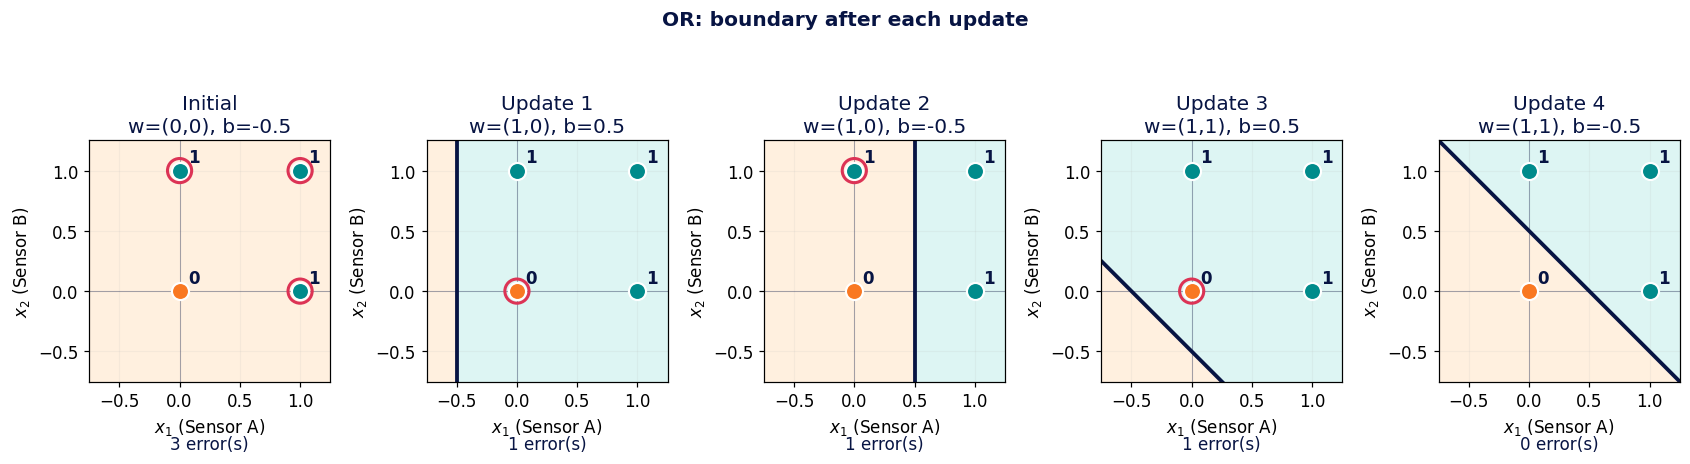

,Step,Pass,x,t,u before,y before,e,w1 after,w2 after,b after,Update?,All-point errors after
0,2,1,"(1, 0)",1,-0.5,0,1,1.0,0.0,0.5,True,1
1,5,2,"(0, 0)",0,0.5,1,-1,1.0,0.0,-0.5,True,1
2,7,2,"(0, 1)",1,-0.5,0,1,1.0,1.0,0.5,True,1
3,9,3,"(0, 0)",0,0.5,1,-1,1.0,1.0,-0.5,True,0


In [5]:
def boundary(ax, w, b, **kwargs):
    """直線を描画します。ゼロ重みでは直線はありません。 / Draw a boundary unless w is zero."""
    if np.linalg.norm(w) < 1e-12:
        return
    if abs(w[1]) < 1e-12:
        ax.axvline(-b / w[0], **kwargs)
    else:
        xx = np.array([-.75, 1.25])
        ax.plot(xx, -(w[0] * xx + b) / w[1], **kwargs)

def draw_state(ax, w, b, targets, current=None, old=None, show_w=False):
    """背景は予測、点は正解です。 / Backgrounds show predictions; points show targets."""
    g = np.linspace(-.75, 1.25, 180)
    xx, yy = np.meshgrid(g, g)
    zz = (w[0] * xx + w[1] * yy + b >= 0).astype(int)
    ax.contourf(xx, yy, zz, levels=[-.5, .5, 1.5], cmap=REGIONS)
    ax.axhline(0, color=NAVY, lw=.7, alpha=.35)
    ax.axvline(0, color=NAVY, lw=.7, alpha=.35)
    if old is not None:
        boundary(ax, *old, color='#777777', ls='--', lw=1.5)
    boundary(ax, w, b, color=NAVY, lw=2.5)
    predictions = predict(X, w, b)
    for i, (point, target, y) in enumerate(zip(X, targets, predictions)):
        ax.scatter(*point, s=125, c=TEAL if target else ORANGE,
                   edgecolors='white', linewidths=1.4, zorder=5)
        ax.text(point[0]+.07, point[1]+.07, str(target), color=NAVY, weight='bold')
        if y != target:
            ax.scatter(*point, s=250, facecolors='none', edgecolors=RED, lw=2, zorder=6)
        if i == current:
            ax.scatter(*point, s=430, facecolors='none', edgecolors='#d59800', lw=2, zorder=7)
    if show_w and np.linalg.norm(w) > 1e-12:
        # 表示範囲に合わせ矢印を縮尺表示します。 / Scale the arrow to fit the view.
        v = w / max(1., np.linalg.norm(w)) * .65
        ax.annotate('', xy=v, xytext=(0, 0), arrowprops={'arrowstyle': '->', 'color': '#9437a6', 'lw': 2})
        ax.text(*(v+.05), 'w (scaled)', color='#9437a6')
    ax.set(xlim=(-.75,1.25), ylim=(-.75,1.25), xlabel='$x_1$ (Sensor A)',
           ylabel='$x_2$ (Sensor B)', aspect='equal')
    ax.set_xticks([-.5,0,.5,1]); ax.set_yticks([-.5,0,.5,1])
    ax.grid(alpha=.12)

def show_overview(result):
    """更新が起きた状態だけを並べます。 / Show snapshots after parameter updates."""
    states = [r for r in result['records'] if r['step'] == 0 or r['changed']]
    if len(states) > 9:
        # 非収束時は末尾の状態を表示します。 / Limit the overview for a nonconvergent trace.
        states = [states[0]] + states[-8:]
    fig, axes = plt.subplots(1, len(states), figsize=(3.1*len(states), 4.4), squeeze=False)
    for ax, r in zip(axes[0], states):
        draw_state(ax, r['w'], r['b'], result['targets'])
        label = 'Initial' if r['step'] == 0 else f"Update {r['updates']}"
        ax.set_title(f"{label}\nw=({r['w'][0]:g},{r['w'][1]:g}), b={r['b']:g}", color=NAVY)
        ax.text(.5, -.28, f"{r['errors']} error(s)", transform=ax.transAxes, ha='center', color=NAVY)
    fig.suptitle(f"{result['task']}: boundary after each update", color=NAVY, weight='bold')
    fig.tight_layout()
    display(fig)
    plt.close(fig)

show_overview(slide_result)
display(trace_table(slide_result, updates_only=True))
print(f"更新回数 / Updates: {slide_result['updates']}; 確認を含む周回数 / Passes: {slide_result['epochs']}")

## インタラクティブ操作 / Interactive controls

赤い輪は**選択中の更新前／後のモデル**による誤分類です。金色の輪は処理中のサンプルです。  
Red rings mark mistakes by the selected **before/after model**; the gold ring marks the current sample.

「誤分類数」はその時点のモデルを**4点すべて**で評価した数であり、その周回で起きた更新回数とは異なります。  
The error count evaluates the current model on **all four points**; it is not the number of updates during a pass.

スライダーは保存済みの履歴を再生します。巻き戻しても学習済み履歴を壊しません。  
The slider replays a recorded trace, so rewinding does not modify training history.

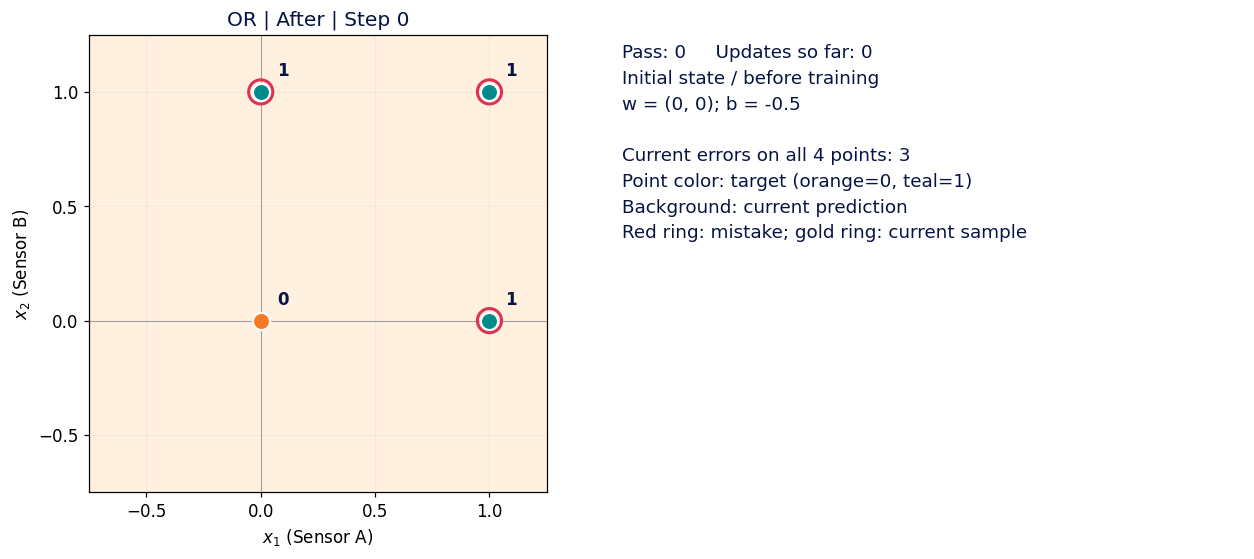

,x1,x2,正解 / Target,スコア / Score,予測 / Prediction,正解か / Correct?
0,0,0,0,-0.5,0,True
1,1,0,1,-0.5,0,False
2,0,1,1,-0.5,0,False
3,1,1,1,-0.5,0,False


In [7]:
# コントロールを作成します。 / Create the interactive controls.
task_widget = widgets.Dropdown(options=['OR', 'AND', 'XOR'], value='OR', description='課題 / Task')
eta_widget = widgets.FloatSlider(value=1., min=.1, max=2., step=.1, description='学習率 / eta', continuous_update=False)
w1_widget = widgets.FloatText(value=0., description='Initial w1')
w2_widget = widgets.FloatText(value=0., description='Initial w2')
b_widget = widgets.FloatText(value=-.5, description='Initial b')
epochs_widget = widgets.IntSlider(value=10, min=1, max=30, description='最大周回 / Max', continuous_update=False)
rebuild_button = widgets.Button(description='再計算 / Rebuild', button_style='primary')
preset_button = widgets.Button(description='スライド設定 / Slide preset', layout=widgets.Layout(width='230px'))
mode_widget = widgets.ToggleButtons(options=[('全サンプル / All samples', 'all'), ('更新のみ / Updates only', 'updates')], value='all')
phase_widget = widgets.ToggleButtons(options=[('更新前 / Before', 'before'), ('更新後 / After', 'after')], value='after')
ghost_widget = widgets.Checkbox(value=True, description='更新前の境界 / Previous boundary')
normal_widget = widgets.Checkbox(value=False, description='重みの方向 / Weight direction')
slider = widgets.IntSlider(value=0, min=0, max=1, description='状態 / State', continuous_update=False, layout=widgets.Layout(width='75%'))
play = widgets.Play(value=0, min=0, max=1, interval=1100, description='再生 / Play', repeat=False)
play_link = widgets.jslink((play, 'value'), (slider, 'value'))
back_button = widgets.Button(description='前へ / Back')
next_button = widgets.Button(description='次へ / Next')
reset_button = widgets.Button(description='巻き戻し / Rewind')
status = widgets.HTML()
output_area = widgets.Output()
ui_state = {'result': slide_result, 'indices': [], 'busy': False}

def fmt_vec(v):
    return '(' + ', '.join(f'{z:g}' for z in v) + ')'

def render_current(change=None):
    """選択した状態を再描画します。 / Redraw the selected recorded state."""
    if ui_state['busy'] or not ui_state['indices']:
        return
    result = ui_state['result']
    r = result['records'][ui_state['indices'][slider.value]]
    before = phase_widget.value == 'before' and r['step'] > 0
    w, b = (r['w_before'], r['b_before']) if before else (r['w'], r['b'])
    old = (r['w_before'], r['b_before']) if ghost_widget.value and r['changed'] and not before else None
    with output_area:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={'width_ratios': [1, 1.12]})
        draw_state(axes[0], w, b, result['targets'], current=r['sample'], old=old, show_w=normal_widget.value)
        axes[0].set_title(f"{result['task']} | {'Before' if before else 'After'} | Step {r['step']}", color=NAVY)
        axes[1].axis('off')
        lines = [f"Pass: {r['epoch']}     Updates so far: {r['updates']}"]
        if r['step'] == 0:
            lines += ['Initial state / 学習前', f"w = {fmt_vec(w)}; b = {b:g}"]
        else:
            dw = result['eta'] * r['e'] * r['x']
            db = result['eta'] * r['e']
            # グラフは英語、数値表とコメントは日英併記です。 / Plots use English; tables/comments are bilingual.
            lines += [f"Input x = {fmt_vec(r['x'])}, target t = {r['target']}",
                      f"Before: u = {r['u_before']:g}, y = {r['y_before']}",
                      f"e = t - y = {r['e']:+d}",
                      f"Delta w = eta e x = {fmt_vec(dw)}", f"Delta b = eta e = {db:+g}",
                      f"w: {fmt_vec(r['w_before'])} -> {fmt_vec(r['w'])}",
                      f"b: {r['b_before']:g} -> {r['b']:g}",
                      'UPDATE' if r['changed'] else 'CORRECT: NO UPDATE']
        lines += ['', f"Current errors on all 4 points: {int(np.sum(predict(X,w,b)!=result['targets']))}",
                  'Point color: target (orange=0, teal=1)',
                  'Background: current prediction', 'Red ring: mistake; gold ring: current sample']
        # 日本語フォント依存を避けます。 / Avoid relying on installed Japanese plotting fonts.
        lines = [s.replace(' / 学習前', ' / before training') for s in lines]
        axes[1].text(.01,.98,'\n'.join(lines),va='top',fontsize=12,color=NAVY,linespacing=1.55)
        fig.tight_layout(); display(fig); plt.close(fig)
        scores = X @ w + b
        display(pd.DataFrame({'x1': X[:,0].astype(int), 'x2': X[:,1].astype(int),
            '正解 / Target': result['targets'], 'スコア / Score': scores,
            '予測 / Prediction': predict(X,w,b),
            '正解か / Correct?': predict(X,w,b) == result['targets']}))
    back_button.disabled = slider.value == 0
    next_button.disabled = slider.value == slider.max

def refresh_indices(change=None):
    """全サンプル／更新のみの表示を切り替えます。 / Switch between samples and updates."""
    play.playing = False
    ui_state['busy'] = True
    result = ui_state['result']
    ui_state['indices'] = [i for i,r in enumerate(result['records'])
        if mode_widget.value == 'all' or i == 0 or r['changed']]
    slider.value = 0; play.value = 0
    slider.max = len(ui_state['indices'])-1; play.max = slider.max
    ui_state['busy'] = False
    conclusion = ('更新なしの周回で停止 / Stopped after an error-free pass' if result['converged']
        else '最大周回で停止・収束未確認 / Limit reached; convergence not confirmed')
    status.value = (f"<b>{result['task']}</b> | eta={result['eta']:g} | "
        f"更新 / Updates: {result['updates']} | 周回 / Passes: {result['epochs']}<br>{conclusion}")
    render_current()

def rebuild_demo(button=None):
    """変更された設定で履歴を作り直します。 / Rebuild the trace with the selected settings."""
    try:
        ui_state['result'] = train_trace(task_widget.value, eta_widget.value,
            (w1_widget.value,w2_widget.value), b_widget.value, epochs_widget.value)
    except ValueError as exc:
        status.value = str(exc)
        return
    refresh_indices()

def restore_preset(button=None):
    """スライドと同じ条件に戻します。 / Restore the lecture-slide configuration."""
    task_widget.value='OR'; eta_widget.value=1.; w1_widget.value=0.; w2_widget.value=0.
    b_widget.value=-.5; epochs_widget.value=10; phase_widget.value='after'
    rebuild_demo()

def move_step(delta):
    play.playing=False
    slider.value=max(0,min(slider.max,slider.value+delta))

back_button.on_click(lambda button: move_step(-1))
next_button.on_click(lambda button: move_step(1))
reset_button.on_click(lambda button: move_step(-slider.value))
rebuild_button.on_click(rebuild_demo); preset_button.on_click(restore_preset)
mode_widget.observe(refresh_indices,names='value')
for control in (slider,phase_widget,ghost_widget,normal_widget):
    control.observe(render_current,names='value')

controls = widgets.VBox([
    widgets.HTML('<b>設定変更後は再計算を押してください。 / Click Rebuild after changing settings.</b>'),
    widgets.HBox([task_widget,eta_widget,epochs_widget],layout=widgets.Layout(flex_flow='row wrap')),
    widgets.HBox([w1_widget,w2_widget,b_widget],layout=widgets.Layout(flex_flow='row wrap')),
    widgets.HBox([rebuild_button,preset_button]),mode_widget,phase_widget,
    widgets.HBox([ghost_widget,normal_widget],layout=widgets.Layout(flex_flow='row wrap')),
    widgets.HBox([back_button,next_button,reset_button,play]),slider,status,output_area])
display(controls)
refresh_indices()

## 確認と発展 / Checks and extension

- 初期状態では $w=0$ なので境界直線はなく、全点の予測は0です。  
  Initially $w=0$: there is no boundary line and every prediction is 0.
- スライド条件では4回の更新、4周目に更新がないことを確認します。  
  The slide configuration makes four updates, with an update-free fourth pass.
- $(0,0)$ で誤ると $\Delta w=0$ ですが、$\Delta b\ne0$ です。境界は平行移動します。  
  A mistake at $(0,0)$ changes only the bias, translating the boundary.
- ANDでは両センサーが反応した $(1,1)$ だけが正例です。課題を選択して再計算してください。  
  AND has a positive target only at $(1,1)$, when both sensors are active. Select the task and click Rebuild.
- XORに切り替えると、単体の直線では4点を分離できません。停止上限に達しても学習成功ではありません。  
  XOR is not linearly separable; reaching the pass limit is not successful convergence.
- 学習率や初期値を変えると更新回数や最終境界が変わることがあります。最大マージンを求める学習ではありません。  
  Learning rate and initialization may change the trajectory and final separator; this rule does not maximize the margin.

### 教員向けの使い方 / Suggested lecture sequence
**全サンプル表示 → 更新前後の比較 → 更新のみ表示 → AND・XORとの対比**。  
**All samples → before/after comparison → updates only → contrast with AND and XOR**.

### 参照 / References
- [ipywidgets: Widget List](https://ipywidgets.readthedocs.io/en/stable/examples/Widget%20List.html)
- [Google Colab widget support](https://github.com/googlecolab/colabtools/blob/main/google/colab/output/_widgets.py)

In [9]:
# スライドとの一致を自動確認します。 / Verify agreement with the lecture example.
check = train_trace()
updates = [r for r in check['records'] if r['changed']]
expected = [([1,0],.5),([1,0],-.5),([1,1],.5),([1,1],-.5)]
assert check['converged'] and check['epochs']==4 and len(updates)==4
for r,(w,b) in zip(updates,expected):
    np.testing.assert_allclose(r['w'],w)
    assert np.isclose(r['b'],b)
np.testing.assert_array_equal(predict(X,updates[-1]['w'],updates[-1]['b']),TARGETS['OR'])
and_check = train_trace('AND')
assert and_check['converged']
np.testing.assert_array_equal(predict(X,and_check['records'][-1]['w'],and_check['records'][-1]['b']),TARGETS['AND'])
assert not train_trace('XOR',max_epochs=10)['converged']
print('確認OK：4回の更新と最終判定がスライドに一致します。')
print('Checks passed: four updates and the final predictions match the slide.')
print('ANDの4点も正分類を確認しました。 / All four AND targets are also classified correctly.')

確認OK：4回の更新と最終判定がスライドに一致します。
Checks passed: four updates and the final predictions match the slide.
ANDの4点も正分類を確認しました。 / All four AND targets are also classified correctly.
